### Level 4: Basic Analysis and Visualization

In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Load dataset
df=pd.read_csv(r"C:\Users\Dell\train_schedule_verified.csv")
df.head()

,SN,Train_No,Station_Code,1A,2A,3A,SL,Station_Name,Route_Number,Arrival_time,Departure_Time,Distance
0,1,107,SWV,100,100,100,100,SAWANTWADI R,1,00:00:00,10:25:00,0
1,2,107,THVM,260,228,196,164,THIVIM,1,11:06:00,11:08:00,32
2,3,107,KRMI,345,296,247,198,KARMALI,1,11:28:00,11:30:00,49
3,4,107,MAO,490,412,334,256,MADGOAN JN.,1,12:10:00,00:00:00,78
4,1,108,MAO,100,100,100,100,MADGOAN JN.,1,00:00:00,20:30:00,0


In [3]:
#basic information
df.shape

(186074, 12)

In [4]:
df.columns

Index(['SN', 'Train_No', 'Station_Code', '1A', '2A', '3A', 'SL',
       'Station_Name', 'Route_Number', 'Arrival_time', 'Departure_Time',
       'Distance'],
      dtype='object')

In [5]:
# Check the data types
print(df[['Arrival_time', 'Departure_Time']].dtypes)

Arrival_time      object
Departure_Time    object
dtype: object


In [6]:
# View sample time values
df[['Train_No', 'Arrival_time', 'Departure_Time']].head(10)

,Train_No,Arrival_time,Departure_Time
0,107,00:00:00,10:25:00
1,107,11:06:00,11:08:00
2,107,11:28:00,11:30:00
3,107,12:10:00,00:00:00
4,108,00:00:00,20:30:00
5,108,21:04:00,21:06:00
6,108,21:26:00,21:28:00
7,108,22:25:00,00:00:00
8,128,19:40:00,19:40:00
9,128,20:18:00,20:20:00


In [7]:
# Convert arrival time to datetime
df['Arrival_time'] = pd.to_datetime(df['Arrival_time'],format='%H:%M:%S')

# Convert departure time to datetime
df['Departure_Time'] = pd.to_datetime(df['Departure_Time'],format='%H:%M:%S')

In [8]:
#verify conversion
print(df[['Arrival_time', 'Departure_Time']].dtypes)

Arrival_time      datetime64[ns]
Departure_Time    datetime64[ns]
dtype: object


In [9]:
df[['Train_No', 'Arrival_time', 'Departure_Time']].head(10)

,Train_No,Arrival_time,Departure_Time
0,107,1900-01-01 00:00:00,1900-01-01 10:25:00
1,107,1900-01-01 11:06:00,1900-01-01 11:08:00
2,107,1900-01-01 11:28:00,1900-01-01 11:30:00
3,107,1900-01-01 12:10:00,1900-01-01 00:00:00
4,108,1900-01-01 00:00:00,1900-01-01 20:30:00
5,108,1900-01-01 21:04:00,1900-01-01 21:06:00
6,108,1900-01-01 21:26:00,1900-01-01 21:28:00
7,108,1900-01-01 22:25:00,1900-01-01 00:00:00
8,128,1900-01-01 19:40:00,1900-01-01 19:40:00
9,128,1900-01-01 20:18:00,1900-01-01 20:20:00


In [10]:
#Task 4.1: Compare average journey durations across route types

# Get the first departure and last arrival for each train
journey_times =df.groupby('Train_No').agg(Start_Time=('Departure_Time', 'first'),
    End_Time=('Arrival_time', 'last')).reset_index()

# Calculate journey duration
journey_times['Journey_Duration'] = (
    journey_times['End_Time'] - journey_times['Start_Time'])

# Correct negative durations for journeys crossing midnight once
journey_times.loc[journey_times['Journey_Duration'] < pd.Timedelta(0),
    'Journey_Duration'] += pd.Timedelta(days=1)

In [11]:
# Convert duration into hours
journey_times['Journey_Duration_Hours'] = (
    journey_times['Journey_Duration'].dt.total_seconds() / 3600)

# Display the results
journey_times.head(10)

,Train_No,Start_Time,End_Time,Journey_Duration,Journey_Duration_Hours
0,107,1900-01-01 10:25:00,1900-01-01 12:10:00,0 days 01:45:00,1.750000
1,108,1900-01-01 20:30:00,1900-01-01 22:25:00,0 days 01:55:00,1.916667
2,128,1900-01-01 19:40:00,1900-01-01 17:45:00,0 days 22:05:00,22.083333
3,290,1900-01-01 18:30:00,1900-01-01 02:30:00,0 days 08:00:00,8.000000
4,401,1900-01-01 21:30:00,1900-01-01 10:00:00,0 days 12:30:00,12.500000
5,421,1900-01-01 23:00:00,1900-01-01 08:00:00,0 days 09:00:00,9.000000
6,422,1900-01-01 11:45:00,1900-01-01 14:30:00,0 days 02:45:00,2.750000
7,477,1900-01-01 12:10:00,1900-01-01 15:20:00,0 days 03:10:00,3.166667
8,502,1900-01-01 10:30:00,1900-01-01 09:30:00,0 days 23:00:00,23.000000
9,504,1900-01-01 09:00:00,1900-01-01 10:00:00,0 days 01:00:00,1.000000


In [12]:
# Find the maximum recorded distance for each train
route_distance = (df.groupby('Train_No')['Distance'].max().reset_index())

# Rename the distance column
route_distance = route_distance.rename(columns={'Distance': 'Route_Distance'})

# Display the results
route_distance.head(10)

,Train_No,Route_Distance
0,107,78
1,108,83
2,128,978
3,290,2694
4,401,1618
5,421,1276
6,422,1277
7,477,2616
8,502,1206
9,504,1313


In [13]:
# Define a function to classify routes
def classify_route(distance):
    if distance <= 38:
        return 'Short'
    elif distance <= 324:
        return 'Medium'
    else:
        return 'Long'

In [14]:
# Apply route classification
route_distance['Route_Category'] = (
    route_distance['Route_Distance'].apply(classify_route))

# Check route categories
route_distance.head(10)

,Train_No,Route_Distance,Route_Category
0,107,78,Medium
1,108,83,Medium
2,128,978,Long
3,290,2694,Long
4,401,1618,Long
5,421,1276,Long
6,422,1277,Long
7,477,2616,Long
8,502,1206,Long
9,504,1313,Long


In [15]:
# Count trains in each category
print("Number of trains in each route category:")
route_distance['Route_Category'].value_counts()

Number of trains in each route category:


Route_Category
Medium    5502
Short     2834
Long      2777
Name: count, dtype: int64

In [16]:
# Merge the two tables using Train_No
train_analysis = journey_times.merge(route_distance[
    ['Train_No', 'Route_Distance', 'Route_Category']],on='Train_No',how='inner')

# Display the combined data
train_analysis.head(10)

,Train_No,Start_Time,End_Time,Journey_Duration,Journey_Duration_Hours,Route_Distance,Route_Category
0,107,1900-01-01 10:25:00,1900-01-01 12:10:00,0 days 01:45:00,1.750000,78,Medium
1,108,1900-01-01 20:30:00,1900-01-01 22:25:00,0 days 01:55:00,1.916667,83,Medium
2,128,1900-01-01 19:40:00,1900-01-01 17:45:00,0 days 22:05:00,22.083333,978,Long
3,290,1900-01-01 18:30:00,1900-01-01 02:30:00,0 days 08:00:00,8.000000,2694,Long
4,401,1900-01-01 21:30:00,1900-01-01 10:00:00,0 days 12:30:00,12.500000,1618,Long
5,421,1900-01-01 23:00:00,1900-01-01 08:00:00,0 days 09:00:00,9.000000,1276,Long
6,422,1900-01-01 11:45:00,1900-01-01 14:30:00,0 days 02:45:00,2.750000,1277,Long
7,477,1900-01-01 12:10:00,1900-01-01 15:20:00,0 days 03:10:00,3.166667,2616,Long
8,502,1900-01-01 10:30:00,1900-01-01 09:30:00,0 days 23:00:00,23.000000,1206,Long
9,504,1900-01-01 09:00:00,1900-01-01 10:00:00,0 days 01:00:00,1.000000,1313,Long


In [17]:
print("Combined Dataset Shape:", train_analysis.shape)

Combined Dataset Shape: (11113, 7)


In [18]:
# Calculate average duration for each route category
average_duration = (train_analysis.groupby('Route_Category')
    ['Journey_Duration_Hours'].mean().reset_index())

# Rename the column
average_duration = average_duration.rename(
    columns={'Journey_Duration_Hours': 'Average_Duration_Hours'})

# Set a logical category order
category_order = ['Short', 'Medium', 'Long']

average_duration['Route_Category'] = pd.Categorical(
    average_duration['Route_Category'],categories=category_order,ordered=True)

average_duration = average_duration.sort_values('Route_Category')

# Display the comparison
print("Average Journey Duration by Route Category:")
average_duration.round(2)

Average Journey Duration by Route Category:


,Route_Category,Average_Duration_Hours
2,Short,0.74
1,Medium,2.92
0,Long,11.86


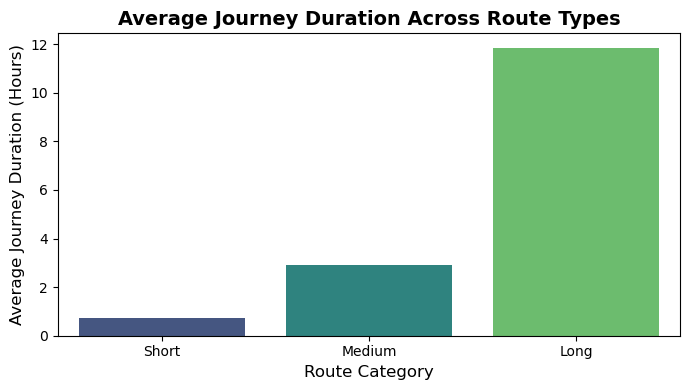

In [19]:
#Visualize average journey duration

# Create a bar chart
plt.figure(figsize=(7,4))

sns.barplot(data=average_duration,x='Route_Category',y='Average_Duration_Hours',
    hue='Route_Category',order=['Short', 'Medium', 'Long'],legend=False,
    palette='viridis')

plt.title('Average Journey Duration Across Route Types',fontsize=14,
          fontweight='bold')
plt.xlabel('Route Category', fontsize=12)
plt.ylabel('Average Journey Duration (Hours)', fontsize=12)

plt.tight_layout()
plt.show()

In [20]:
# Find the route category with the highest average duration
longest_category = average_duration.loc[
    average_duration['Average_Duration_Hours'].idxmax()]

print(
    f"The {longest_category['Route_Category']} route category "
    f"has the highest average journey duration: "
    f"{longest_category['Average_Duration_Hours']:.2f} hours.")

The Long route category has the highest average journey duration: 11.86 hours.


### Task 4.1: Compare Average Journey Durations Across Route Types

**Objective:** To compare the average journey duration of trains categorized into Short, Medium, and Long routes.

**Methodology:**
- Calculated journey duration for each train using its first departure and last arrival time.
- Calculated the maximum recorded route distance for each train.
- Classified routes into Short, Medium, and Long categories.
- Calculated the average journey duration for each category.
- Created a bar chart to compare the average durations visually.

**Key Observation:**
The Long route category has the highest average journey duration of **11.86 hours**.

**Conclusion:**
The analysis indicates that trains in the Long route category generally have longer journey durations in this dataset. The calculated durations should be validated against the original schedules, particularly for journeys involving midnight or endpoint time markers.

In [21]:
#Task 4.2 — Identify High-Traffic Stations

# Count the number of unique trains visiting each station
station_traffic = (df.groupby('Station_Name')['Train_No'].nunique()
    .reset_index(name='Train_Frequency'))

# Sort stations from highest to lowest train frequency
station_traffic = station_traffic.sort_values(by='Train_Frequency',
    ascending=False)

# Display the top 10 high-traffic stations
top_10_stations = station_traffic.head(10)

In [22]:
print("Top 10 High-Traffic Stations:")
top_10_stations

Top 10 High-Traffic Stations:


,Station_Name,Train_Frequency
1755,CST-MUMBAI,1027
3466,KALYAN JN,828
7509,THANE,796
6834,SEALDAH,745
1592,CHENNAI BEAC,738
2950,HOWRAH JN.,699
1773,DADAR,598
2213,DUM DUM JN.,463
4245,KURLA,462
7401,TAMBARAM,434


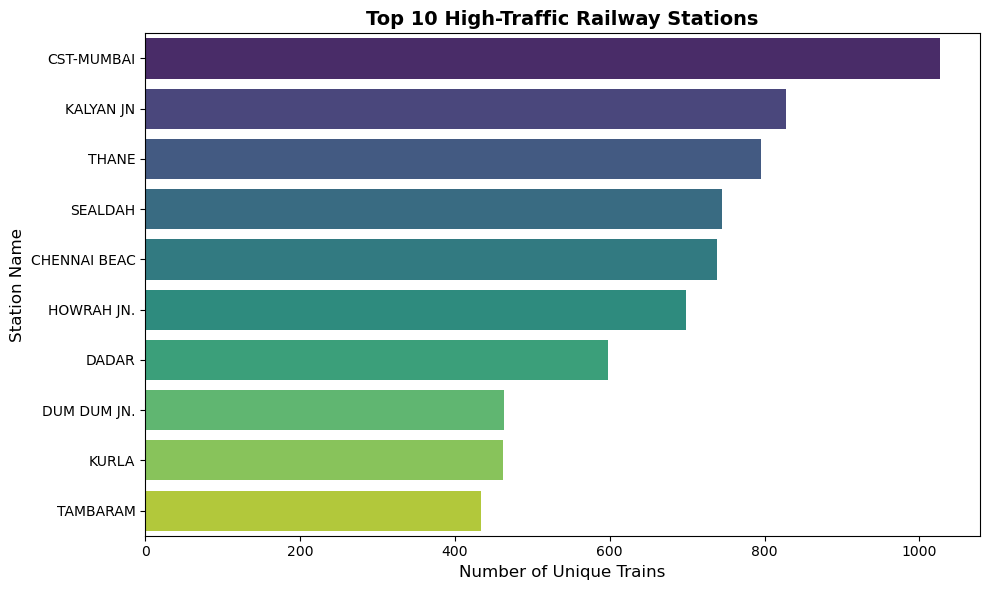

In [23]:
#Visualize the top 10 high-traffic stations

# Select the top 10 stations
top_10_stations = station_traffic.head(10)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

sns.barplot(data=top_10_stations,x='Train_Frequency',y='Station_Name',
    hue='Station_Name',legend=False,palette='viridis')

plt.title('Top 10 High-Traffic Railway Stations',fontsize=14,fontweight='bold')
plt.xlabel('Number of Unique Trains', fontsize=12)
plt.ylabel('Station Name', fontsize=12)
plt.tight_layout()
plt.show()

In [24]:
# Identify the station with the highest train frequency
busiest_station = station_traffic.iloc[0]

print(f"The highest-traffic station is {busiest_station['Station_Name']} "
    f"with {busiest_station['Train_Frequency']} unique trains.")

The highest-traffic station is CST-MUMBAI with 1027 unique trains.


### Task 4.2: Identify High-Traffic Stations

**Objective:** To identify railway stations visited by the highest number of unique trains.

**Methodology:**
- Grouped records by station name.
- Counted unique train numbers for each station.
- Sorted stations in descending order of train frequency.
- Selected the top 10 stations and visualized them using a horizontal bar chart.

**Key Observations:**
- CST-MUMBAI has the highest train frequency, with 1,027 unique trains.
- KALYAN JN ranks second, with 828 unique trains.
- THANE ranks third, with 796 unique trains.
- The results highlight stations with high train activity in this dataset.

**Conclusion:** CST-MUMBAI has the highest recorded train frequency among the stations analyzed. These counts indicate the number of unique trains associated with each station, not the number of passengers or total daily traffic.

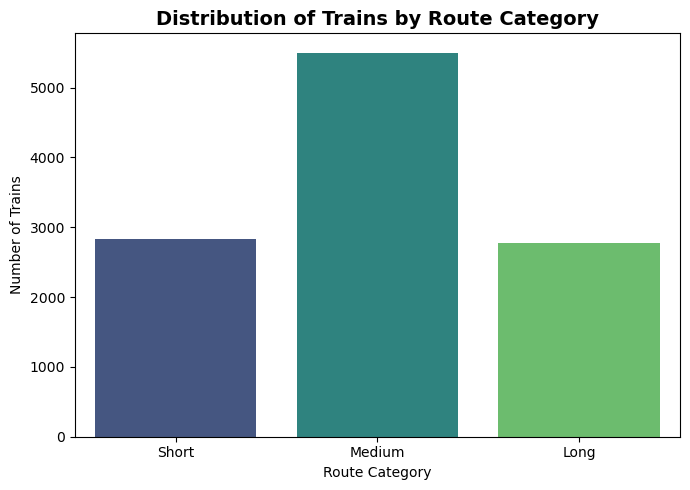

Number of trains by route category:


Route_Category
Short     2834
Medium    5502
Long      2777
Name: count, dtype: int64

In [25]:
#Task 4.3 — Create Basic Visualizations

# Count trains in each route category
route_counts = route_distance['Route_Category'].value_counts().reindex(
    ['Short', 'Medium', 'Long'],fill_value=0)

# Create a bar chart
plt.figure(figsize=(7, 5))

sns.barplot(x=route_counts.index,y=route_counts.values,hue=route_counts.index,
    legend=False,palette='viridis')
plt.title('Distribution of Trains by Route Category'
          ,fontsize=14, fontweight='bold')
plt.xlabel('Route Category')
plt.ylabel('Number of Trains')
plt.tight_layout()
plt.show()
print("Number of trains by route category:")
route_counts

### Chart 1: Distribution of Trains by Route Category

**Observation:**
- Medium routes have the highest count, with 5,502 trains.
- Short routes account for 2,834 trains.
- Long routes account for 2,777 trains.

**Conclusion:**
Medium routes represent approximately half of the trains in the dataset, making them the most common route category based on the distance thresholds used in this analysis.

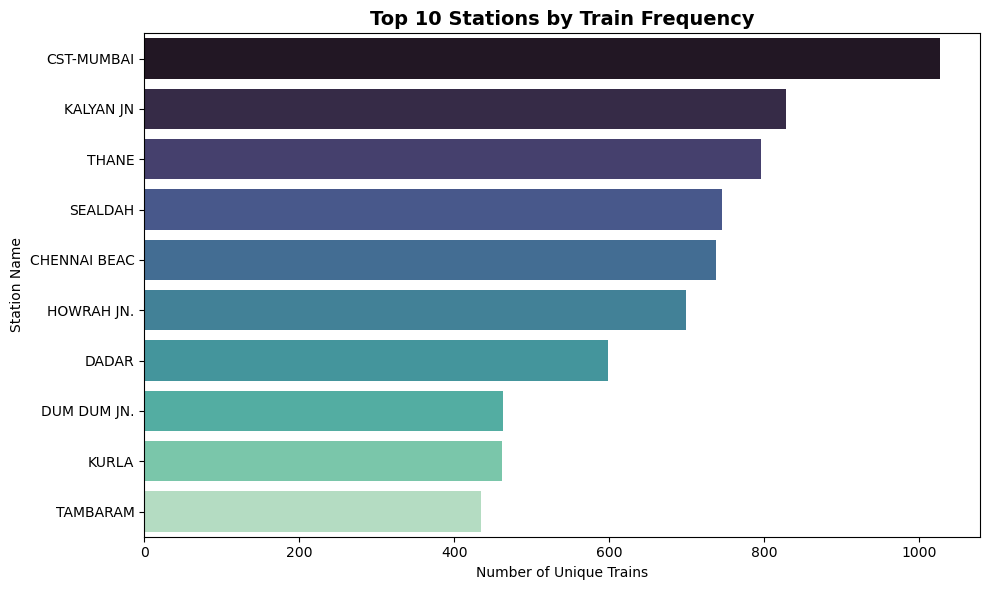

In [26]:
#Chart 2: Top 10 High-Traffic Stations

# Select the top 10 stations
top_10_stations = station_traffic.head(10)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

sns.barplot(data=top_10_stations,x='Train_Frequency',y='Station_Name',
    hue='Station_Name',legend=False,palette='mako')
plt.title('Top 10 Stations by Train Frequency',
          fontsize=14, fontweight='bold')
plt.xlabel('Number of Unique Trains')
plt.ylabel('Station Name')
plt.tight_layout()
plt.show()

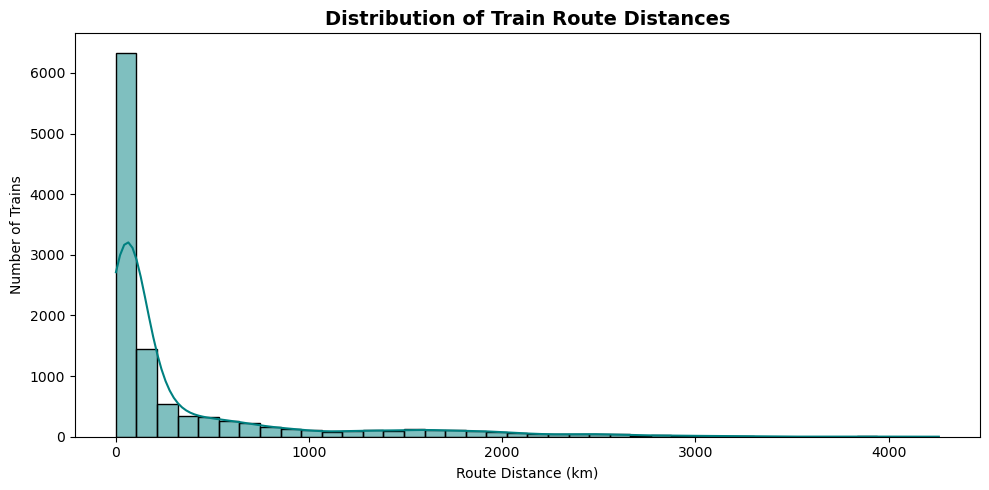

In [27]:
#Chart 3: Route Distance Distribution

# Create a histogram of route distances
plt.figure(figsize=(10, 5))

sns.histplot(data=route_distance,x='Route_Distance',bins=40,kde=True,color='teal')
plt.title('Distribution of Train Route Distances',fontsize=14, fontweight='bold')
plt.xlabel('Route Distance (km)')
plt.ylabel('Number of Trains')
plt.tight_layout()
plt.show()

### Task 4.3: Create Basic Visualizations

**Objective:** To represent train schedule data visually and identify useful patterns.

**Visualizations Created:**

1. **Average Journey Duration Across Route Types:** Compared the average journey duration of Short, Medium, and Long routes.
2. **Top 10 Stations by Train Frequency:** Identified and compared stations with the highest number of unique trains.
3. **Distribution of Trains by Route Category:** Compared the number of trains across Short, Medium, and Long categories.
4. **Distribution of Train Route Distances:** Used a histogram to examine the distribution of route distances.

**Key Observations:**
- Long routes have the highest average journey duration in the calculated results, at 11.86 hours.
- CST-MUMBAI has the highest recorded train frequency, with 1,027 unique trains.
- Medium routes are the most common category, with 5,502 trains.
- The route distance histogram helps reveal how route distances are distributed across trains.

**Conclusion:** The visualizations make it easier to compare route categories, identify high-traffic stations, and understand route distance patterns in the train schedule dataset.

### Task 4.4: Summarize Key Observations

**1. Dataset Overview**
The train schedule dataset contains 186,074 records and 12 columns, representing 11,113 unique trains.

**2. Journey Duration Analysis**
The Long route category has the highest calculated average journey duration, at 11.86 hours.

**3. High-Traffic Stations**
CST-MUMBAI has the highest train frequency, with 1,027 unique trains, followed by KALYAN JN with 828 and THANE with 796.

**4. Route Category Distribution**
Medium routes are the most common category, with 5,502 trains. Short routes account for 2,834 trains, while Long routes account for 2,777 trains.

**5. Route Distance Distribution**
The histogram provides a visual overview of route distances and helps identify common distance ranges and unusually long routes.

**Overall Conclusion**
This analysis explores train journey durations, station traffic frequency, route categories, and route distance patterns. The findings demonstrate how Python, Pandas, Matplotlib, and Seaborn can be used to analyze railway data and communicate insights through visualizations.

**Limitation:** Journey durations should be validated against actual schedules because the dataset contains `00:00:00` endpoint values and does not include explicit travel dates.